# Section 1: Plant growth modelling

Modeling Biosystems - Group `3A`

## 1. Imports

Load NumPy, Matplotlib, and the SciPy ODE solver.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


## 2. Model parameters

Set the reaction rate constants and the kinetic parameters used by the model.

In [2]:
# Parameters
k1 = 1.0
km1 = 0.01
k2 = 0.5
km2 = 0.2

kcat = 0.15
KM = 1.0

k3 = 0.01
k4 = 0.1
k5 = 0.008


## 3. Initial concentrations

Define the starting ligand, receptor, and cytoplasmic transcription factor concentrations. vector: `L, R, LR, LRa, TFc, pTFc, pTFn, TFn`.

In [3]:
# Initial concentrations
L0 = 0.3
R0 = 1.0
TFc0 = 1.0

# Species = [L, R, LR, LRa, TFc, pTFc, pTFn, TFn]


## 4. Differential equations

Define the rate of change for each of the species in `plant_growth(t, y)`.

In [4]:
# Differential equations
def plant_growth(t, y):

    L, R, LR, LRa, TFc, pTFc, pTFn, TFn = y

    dL = -k1*L*R + km1*LR + km2*LRa #hormone
    dR = -k1*L*R + km1*LR + km2*LRa #receptor
    dLR = k1*L*R - km1*LR - k2*LR
    dLRa = k2*LR - km2*LRa

    dTFc = -kcat*LRa*TFc/(KM + TFc) + k5*TFn
    dpTFc = kcat*LRa*TFc/(KM + TFc) - k3*pTFc
    dpTFn = k3*pTFc - k4*pTFn
    dTFn = k4*pTFn - k5*TFn

    return [dL, dR, dLR, dLRa, dTFc, dpTFc, dpTFn, dTFn]


## 5. Initial conditions

Set the remaining starting concentrations and assemble the initial state vector `y0` in the model's species order.

In [5]:
# Script main()

#initial conditions
LR0, LRa0, pTFc0, pTFn0, TFn0 = 0, 0, 0, 0, 0
y0 = [L0, R0, LR0, LRa0, TFc0, pTFc0, pTFn0, TFn0]


## 6. Simulation time

Simulate from time 0 to 500 and request results at 1,000 evenly spaced time points.

In [6]:
#Time interval 
time_interval = (0, 500)
time_points = np.linspace(*time_interval, 1000)


## 7. Solve the ODE system

Integrate the model with `solve_ivp` using the initial conditions and the requested time points.

In [7]:
#Solve the ODE system
solution = solve_ivp(plant_growth, time_interval, y0, t_eval=time_points)


## 8. Extract results

Read the time points returned by the solver and unpack the species concentration arrays.

In [8]:
#Extract results
time_points_evaluation = solution.t # since the function could have stopped earlier than our initial time_points it is good to get them from the solution 
L, R, LR, LRa, TFc, pTFc, pTFn, TFn = solution.y


## 9. Plot species concentrations

Show each species concentration over time in its own subplot.

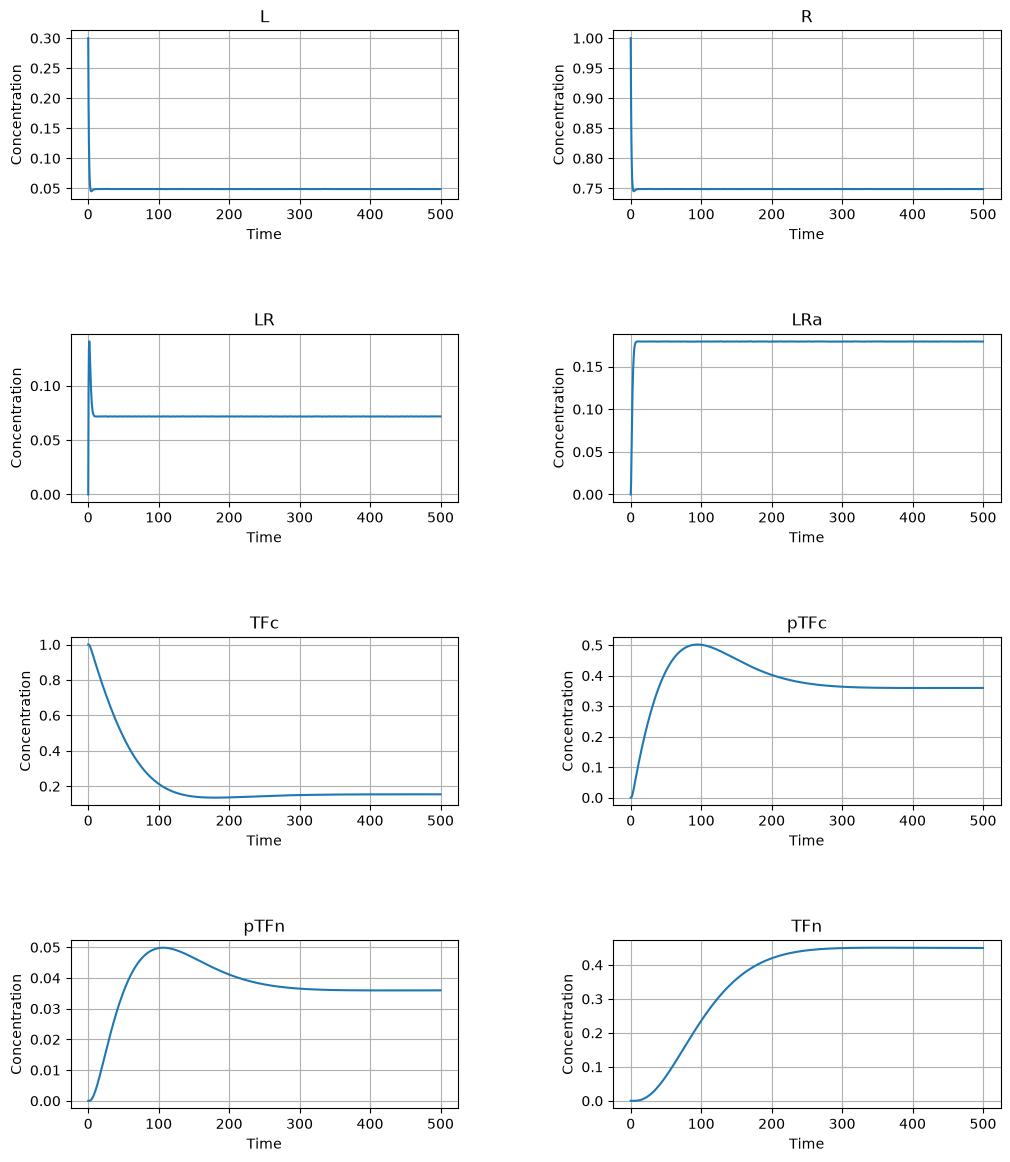

In [9]:
#Ploting our solution
species = ["L", "R", "LR", "LRa", "TFc", "pTFc", "pTFn", "TFn"]

fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for i, ax in enumerate(axes.flat):
    ax.plot(time_points_evaluation, solution.y[i])
    ax.set_title(species[i])
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentration")
    ax.grid(True)

plt.subplots_adjust(hspace=0.8, wspace=0.4)

plt.show()


### 9.1 Analysis of plots
##### 1. Ligand (L)
The ligand concentration decreases rapidly as there are free receptors that it can bind to. They it elevates slightly as receptor complexes dissociate and converges to 0.0489 concentration.
##### 2. Receptor (R)
The receptor behaves very similarly to the ligand as it coverges to 0.7489 due to the higher initial concentration.
##### 3. Ligand–receptor complex (LR)
The complex increases rapidly in the beginning reaching a peak concentration and then it decrases and converges to 0.0718 as it decosiates into L and R or is converted to LRa.
##### 4. Activated receptor (LRa)
The activated receptor increases rapidly as LR startes being activated and converges to 0.1794 as the formation and disociation balance out.   
##### 5. Cytoplasmic unphosphorylated TF (TFc)
The transcription factor's concentration decreases quite a lot as it reaches a minimal level and then reconvers as transcription factor returns from the nucleus and converges to 0.1544.
##### 6. Cytoplasmic phosphorylated TF (pTFc)
The phosphorilated Transcription factor initially increases as cytoplasmic TF gets phosphorilated. It reaches a peak and then converges to 0.3597 as the available TFc falls.
##### 7. Nuclear phosphorylated TF (pTFn)
pTFn starts at zero and increases when pTFc enters the nucleus. It follows the peak and decrease of pTFc a bit delated as it is transported from the cytoplasm. It decreases as dephosphorilation happens and converges to 0.0360.
##### 8. Nuclear unphosphorylated TF (TFn)
TFn gradually increase and reaches it's peak and converges to 0.4499 as the dephosphorylation rate matches the transport out of the nucleus. 

## 10. Calculate conserved totals

Calculate the total ligand, receptor, and transcription factor concentrations by summing their corresponding species.

In [10]:
# Mass conservation

L_total = L + LR + LRa
R_total = R + LR + LRa
TF_total = TFc + pTFc + pTFn + TFn


## 11. Plot mass conservation

Compare the three totals over time to inspect mass conservation.

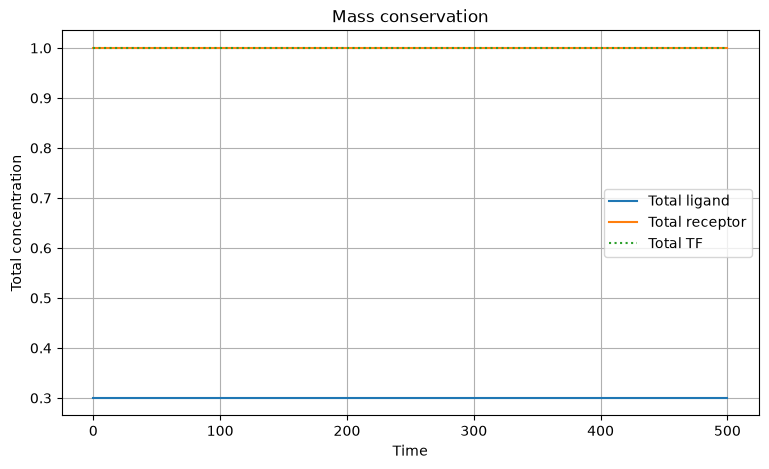

In [11]:
#Plotting Mass consevation

plt.figure(figsize=(9, 5))

plt.plot(solution.t, L_total, label="Total ligand" )
plt.plot(solution.t, R_total, label="Total receptor", )
plt.plot(solution.t, TF_total, label="Total TF", ls="dotted")

plt.xlabel("Time")
plt.ylabel("Total concentration")
plt.title("Mass conservation")
plt.legend()
plt.grid(True)
plt.show()


As expected the total concentration does not change.